In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
red_wine = pd.read_csv("winequality-red.csv", sep=";")

print("Red Wine Dataset Shape:", red_wine.shape)

display(red_wine.head())

FileNotFoundError: [Errno 2] No such file or directory: 'winequality-red.csv'

In [9]:
import os

print("Current folder:", os.getcwd())
print("\nFiles in this folder:")
print(os.listdir())

Current folder: C:\Users\sanaa\OneDrive\Desktop\OIBSIP\DataAnalytics-Level2-Task2-WineQualityPrediction

Files in this folder:
['.ipynb_checkpoints', 'OIBSIP_Level2_Task2_Wine_Quality_Prediction.ipynb', 'wine+quality (1)']


In [10]:
import os

print(os.listdir("wine+quality (1)"))

['winequality-red.csv', 'winequality-white.csv', 'winequality.names']


In [11]:
red_wine = pd.read_csv("wine+quality (1)/winequality-red.csv", sep=";")

print("Red Wine Dataset Shape:", red_wine.shape)
display(red_wine.head())

Red Wine Dataset Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [12]:
white_wine = pd.read_csv("wine+quality (1)/winequality-white.csv", sep=";")

print("White Wine Dataset Shape:", white_wine.shape)
display(white_wine.head())

White Wine Dataset Shape: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [13]:
red_wine["wine_type"] = "Red"
white_wine["wine_type"] = "White"

df = pd.concat([red_wine, white_wine], ignore_index=True)

print("Combined Dataset Shape:", df.shape)
display(df.head())

Combined Dataset Shape: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red


In [14]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDescriptive Statistics:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 689.4 KB

Column Names:
['fixed acidity', 'volatile acidity', 'cit

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [15]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDescriptive Statistics:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 689.4 KB

Column Names:
['fixed acidity', 'volatile acidity', 'cit

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [16]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

Duplicate Rows: 1177


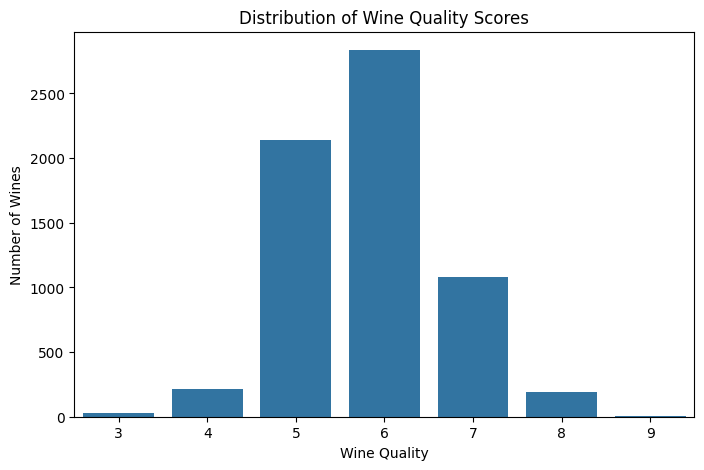

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality")

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")

plt.show()

In [18]:
quality_counts = df["quality"].value_counts().sort_index()

quality_percentage = (quality_counts / len(df)) * 100

quality_distribution = pd.DataFrame({
    "Count": quality_counts,
    "Percentage": quality_percentage.round(2)
})

display(quality_distribution)

,Count,Percentage
quality,,
3,30,0.46
4,216,3.32
5,2138,32.91
6,2836,43.65
7,1079,16.61
8,193,2.97
9,5,0.08


The wine quality dataset is imbalanced because some quality scores, especially 5 and 6, have more samples than other scores. This may affect model predictions because the model can become biased towards majority classes. Stratified sampling helps maintain class proportions during data splitting.

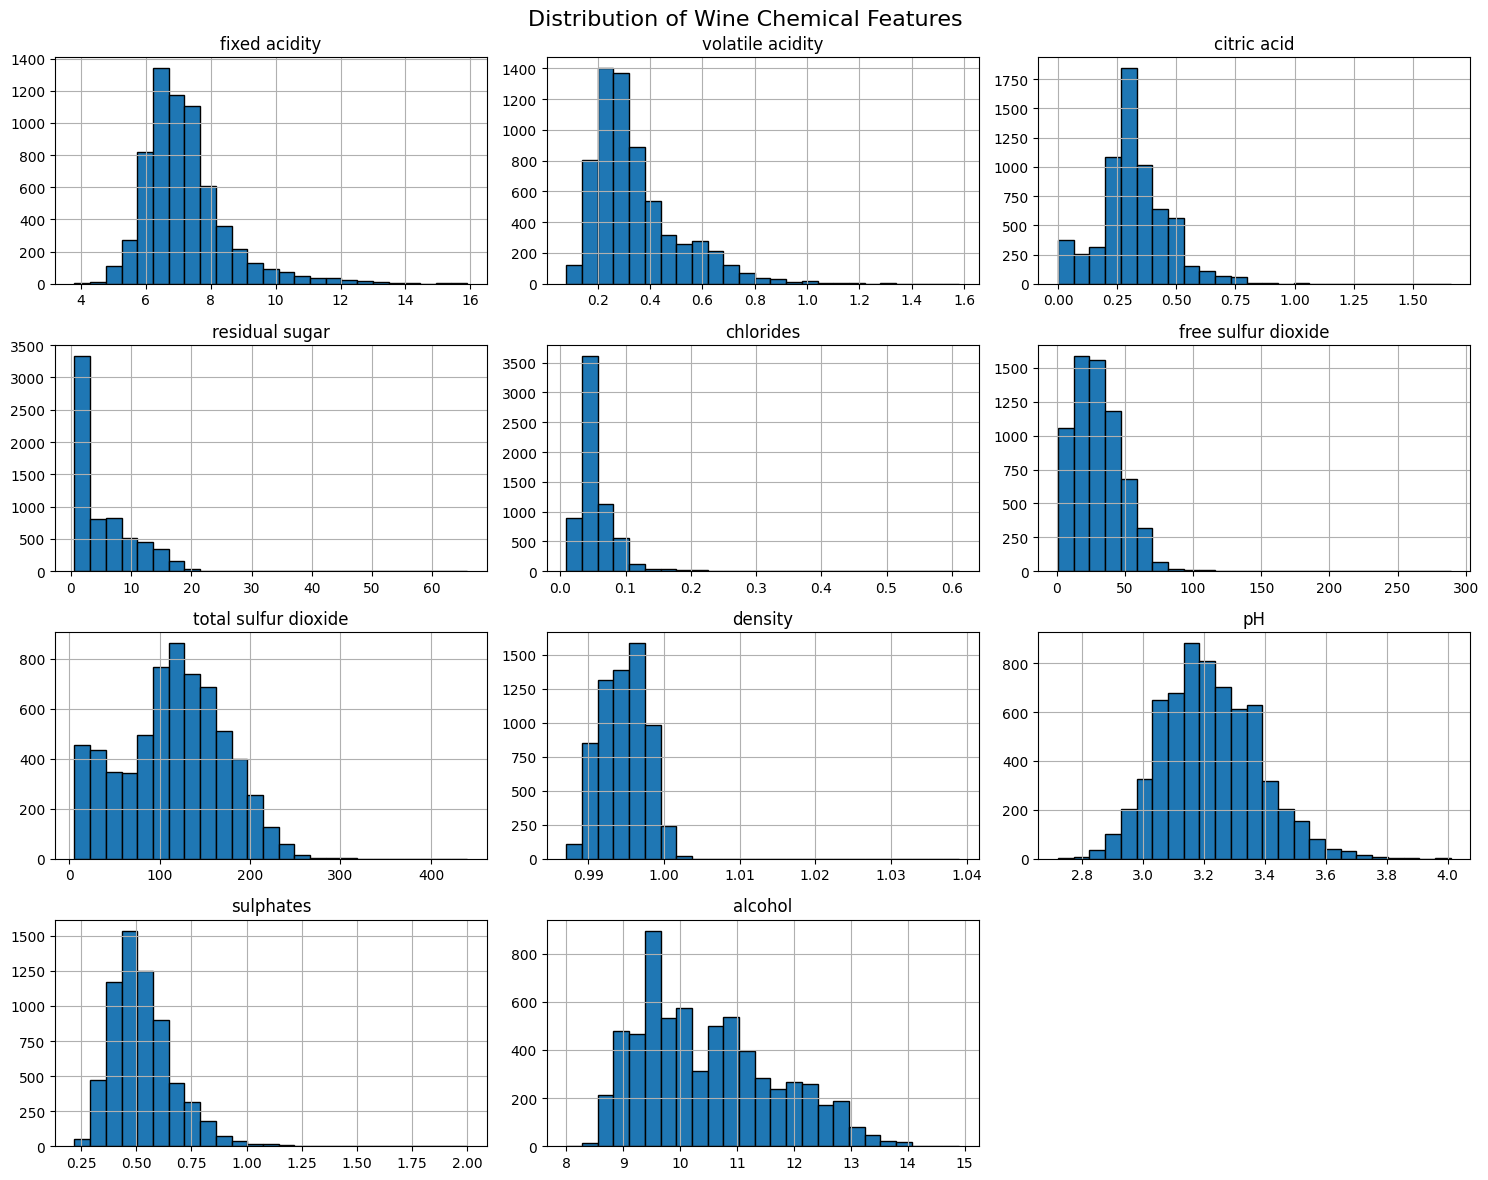

In [20]:
chemical_features = df.select_dtypes(include=["number"]).columns.drop("quality")

df[chemical_features].hist(
    figsize=(15, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Wine Chemical Features", fontsize=16)
plt.tight_layout()
plt.show()

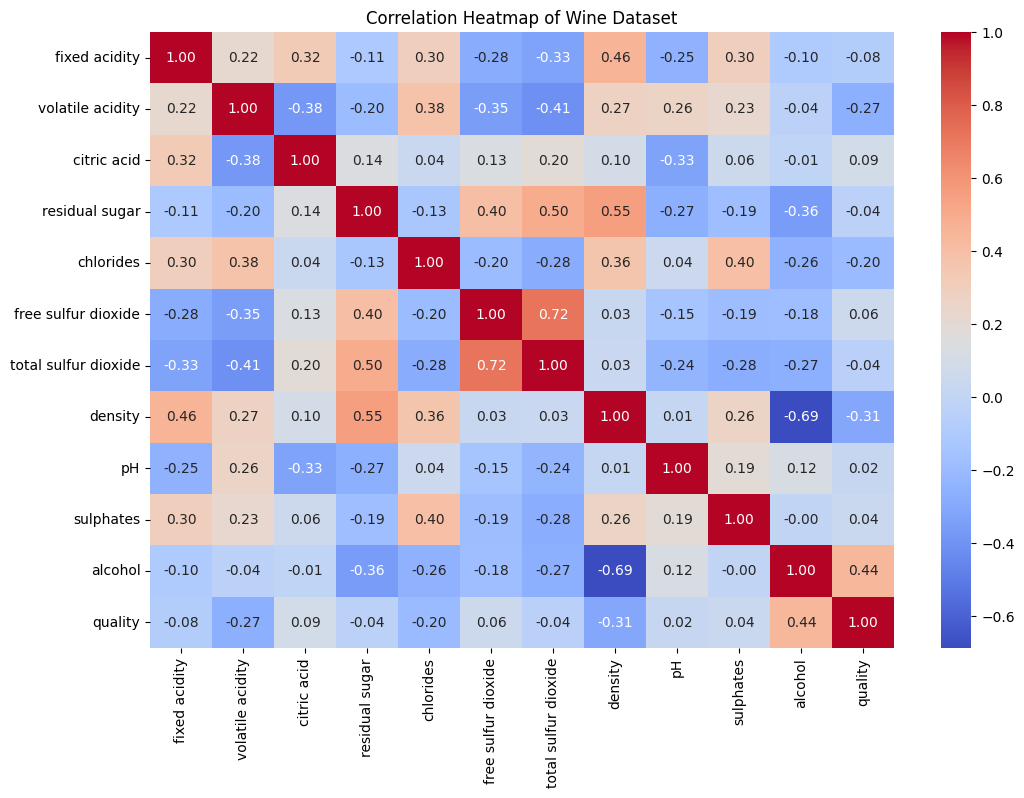

In [21]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=["number"]).corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Wine Dataset")
plt.show()

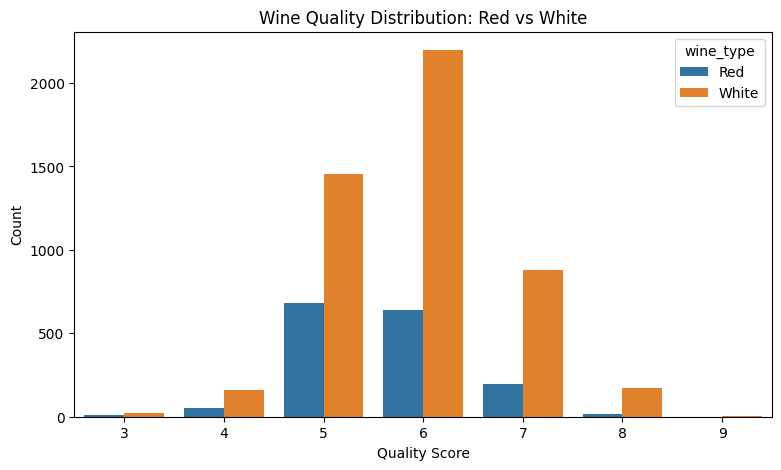

In [22]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="quality", hue="wine_type")

plt.title("Wine Quality Distribution: Red vs White")
plt.xlabel("Quality Score")
plt.ylabel("Count")

plt.show()

In [23]:
def classify_quality(score):
    if score <= 4:
        return "Low"
    elif score <= 6:
        return "Medium"
    else:
        return "High"


df["quality_category"] = df["quality"].apply(classify_quality)

print("New Quality Category Distribution:")
display(df["quality_category"].value_counts())

New Quality Category Distribution:


quality_category
Medium    4974
High      1277
Low        246
Name: count, dtype: int64

In [24]:
X = df.drop(columns=["quality", "quality_category"])
y = df["quality_category"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Input Features Shape: (6497, 12)
Target Shape: (6497,)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,Red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,Red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,Red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,Red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,Red


In [25]:
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Categorical Features: ['wine_type']


In [26]:
X = pd.get_dummies(X, columns=categorical_features, drop_first=True)

print("Encoding completed!")
display(X.head())

Encoding completed!


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type_White
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,False
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,False
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,False
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,False
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,False


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Data Shape: (5197, 12)
Testing Data Shape: (1300, 12)

Training Class Distribution:
quality_category
Medium    0.766
High      0.196
Low       0.038
Name: proportion, dtype: float64

Testing Class Distribution:
quality_category
Medium    0.765
High      0.197
Low       0.038
Name: proportion, dtype: float64


In [28]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [29]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


In [30]:
sgd_model = SGDClassifier(
    max_iter=1000,
    random_state=42
)

sgd_model.fit(X_train_scaled, y_train)

sgd_pred = sgd_model.predict(X_test_scaled)

print("SGD Classifier training completed!")

SGD Classifier training completed!


In [31]:
svc_model = SVC(kernel="rbf")

svc_model.fit(X_train_scaled, y_train)

svc_pred = svc_model.predict(X_test_scaled)

print("SVC training completed!")

SVC training completed!


In [32]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 85.23 %

Classification Report:
              precision    recall  f1-score   support

        High       0.79      0.57      0.66       256
         Low       1.00      0.12      0.22        49
      Medium       0.86      0.96      0.91       995

    accuracy                           0.85      1300
   macro avg       0.88      0.55      0.60      1300
weighted avg       0.85      0.85      0.83      1300


Confusion Matrix:
[[146   0 110]
 [  0   6  43]
 [ 39   0 956]]


In [33]:
sgd_accuracy = accuracy_score(y_test, sgd_pred)

print("SGD Classifier Accuracy:", round(sgd_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, sgd_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, sgd_pred))

SGD Classifier Accuracy: 76.46 %

Classification Report:
              precision    recall  f1-score   support

        High       0.49      0.13      0.20       256
         Low       0.00      0.00      0.00        49
      Medium       0.78      0.97      0.86       995

    accuracy                           0.76      1300
   macro avg       0.42      0.36      0.36      1300
weighted avg       0.69      0.76      0.70      1300


Confusion Matrix:
[[ 33   0 223]
 [  0   0  49]
 [ 34   0 961]]


C:\Users\sanaa\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sanaa\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sanaa\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

In [34]:
svc_accuracy = accuracy_score(y_test, svc_pred)

print("SVC Accuracy:", round(svc_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, svc_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svc_pred))

SVC Accuracy: 78.46 %

Classification Report:
              precision    recall  f1-score   support

        High       0.63      0.24      0.35       256
         Low       0.00      0.00      0.00        49
      Medium       0.80      0.96      0.87       995

    accuracy                           0.78      1300
   macro avg       0.48      0.40      0.41      1300
weighted avg       0.73      0.78      0.74      1300


Confusion Matrix:
[[ 61   0 195]
 [  0   0  49]
 [ 36   0 959]]


C:\Users\sanaa\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sanaa\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sanaa\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

What to observe:
- Accuracy: Overall percentage of correct predictions.
- Precision: How many predicted class samples were correct.
- Recall: How many actual class samples were correctly identified.
- F1-score: Balance between precision and recall.
- Confusion matrix: Shows correct and incorrect predictions for each class.

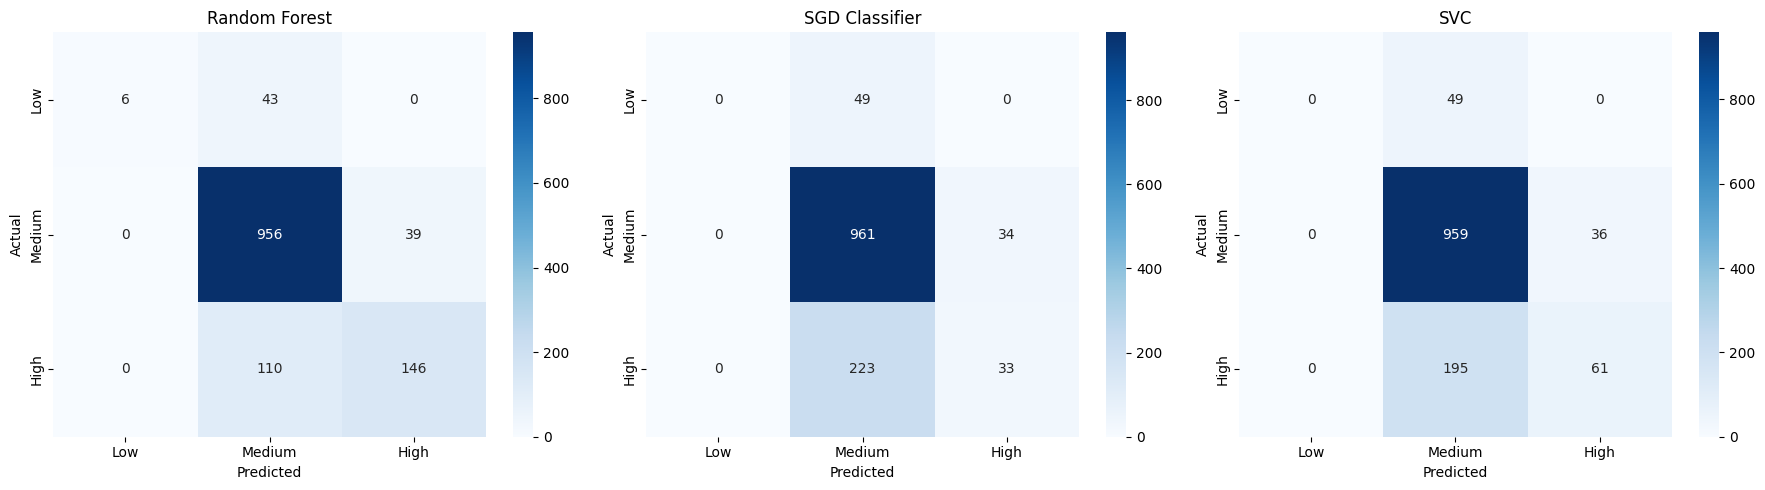

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ("Random Forest", rf_pred),
    ("SGD Classifier", sgd_pred),
    ("SVC", svc_pred)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["Low", "Medium", "High"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

,Feature,Importance
10,alcohol,0.135810
7,density,0.113643
1,volatile acidity,0.092809
4,chlorides,0.088145
6,total sulfur dioxide,0.085990
5,free sulfur dioxide,0.085665
3,residual sugar,0.084376
8,pH,0.084235
9,sulphates,0.082269
0,fixed acidity,0.071974


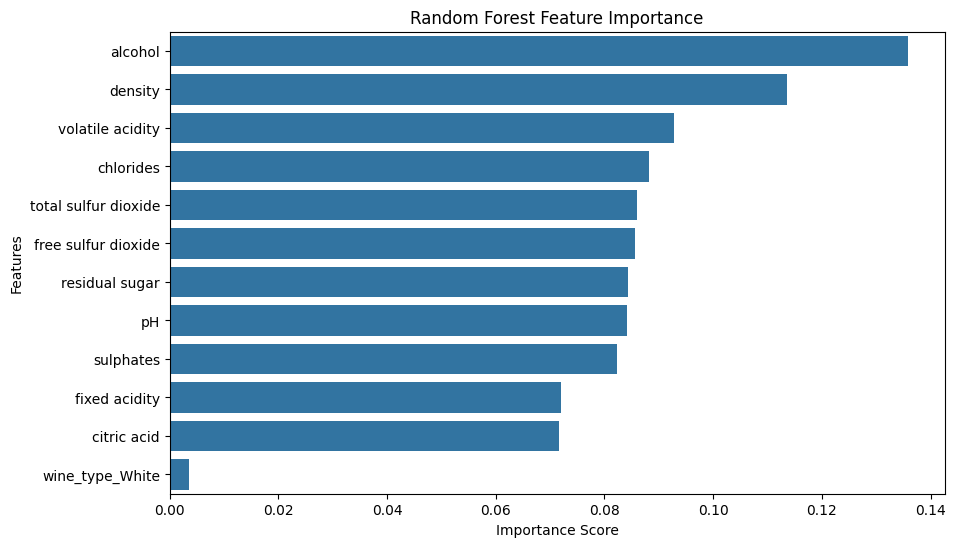

In [36]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [37]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SGD Classifier",
        "SVC"
    ],
    "Accuracy (%)": [
        rf_accuracy * 100,
        sgd_accuracy * 100,
        svc_accuracy * 100
    ]
})

model_comparison["Accuracy (%)"] = model_comparison["Accuracy (%)"].round(2)

display(model_comparison)

,Model,Accuracy (%)
0,Random Forest,85.23
1,SGD Classifier,76.46
2,SVC,78.46


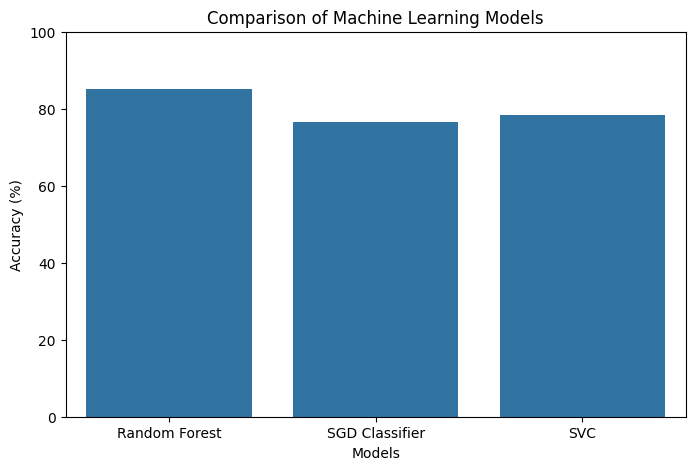

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [39]:
import os

os.makedirs("Outputs", exist_ok=True)

print("Outputs folder is ready!")

Outputs folder is ready!


In [40]:
model_comparison.to_csv(
    "Outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [41]:
feature_importance.to_csv(
    "Outputs/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [42]:
predictions_df = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Random Forest Prediction": rf_pred,
    "SGD Prediction": sgd_pred,
    "SVC Prediction": svc_pred
})

predictions_df.to_csv(
    "Outputs/wine_quality_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!


## Conclusion

In this project, we developed a Wine Quality Prediction system using machine learning classification algorithms.

- Loaded and analyzed the Red and White Wine datasets.
- Performed Exploratory Data Analysis (EDA) using graphs and a correlation heatmap.
- Converted wine quality scores into Low, Medium and High categories.
- Applied feature encoding, scaling and stratified train-test splitting.
- Trained three machine learning models: Random Forest, SGD Classifier and SVC.
- Evaluated the models using accuracy, precision, recall, F1-score and confusion matrices.
- Identified important features using Random Forest feature importance.
- Compared all three models to understand their performance.

**Final Result:** The model with the highest test accuracy performed best on this dataset. This project demonstrates how machine learning can be used to predict wine quality based on its chemical properties.